In [1]:
source('../../../R/preamble.R')

freqplot = function(df, spacing = 0.00, ncol = 4){
    ggplot(df) + aes(gen, freq + spacing*dense_rank(pos), col = pos, group = tid) + 
    geom_line() + geom_point(size = 0.3) +
    #scale_x_continuous(breaks = 0:16) +
    facet_wrap(~pop, ncol = ncol) +
    labs(x = 'Generation', y = 'Frequency')
    }

fpop = function(n = 5) facet_wrap(~pop, ncol = n)

conf = 0.95

# Data from read scrapping
See P0. That should be more reliable than Breseq estimates.

In [2]:
# Indicative estimate of coverage for each sample
junctions_counts = read.tsv('../../../datasets/genomics/09_phage_fhuA/intermediate/junctions_counts.tsv') %>% 
    mutate(        
        pop = substr(name, 2, 2),
        gen = as.integer(substr(name, 3, 4))
        )

name_to_coverage = junctions_counts %>%
    filter(site != 'phag') %>%
    group_by(name, site) %>%
    summarise(n_total = sum(n)) %>%
    group_by(name) %>%
    summarise(coverage = mean(n_total))

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by name and site.
ℹ Output is grouped by name.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(name, site))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


The circular phage is detected in the populations that produce it.
This is not super useful because the samples weren't all sequenced in exponential phase, and the preparation may vary.

In [3]:
library(ggh4x)


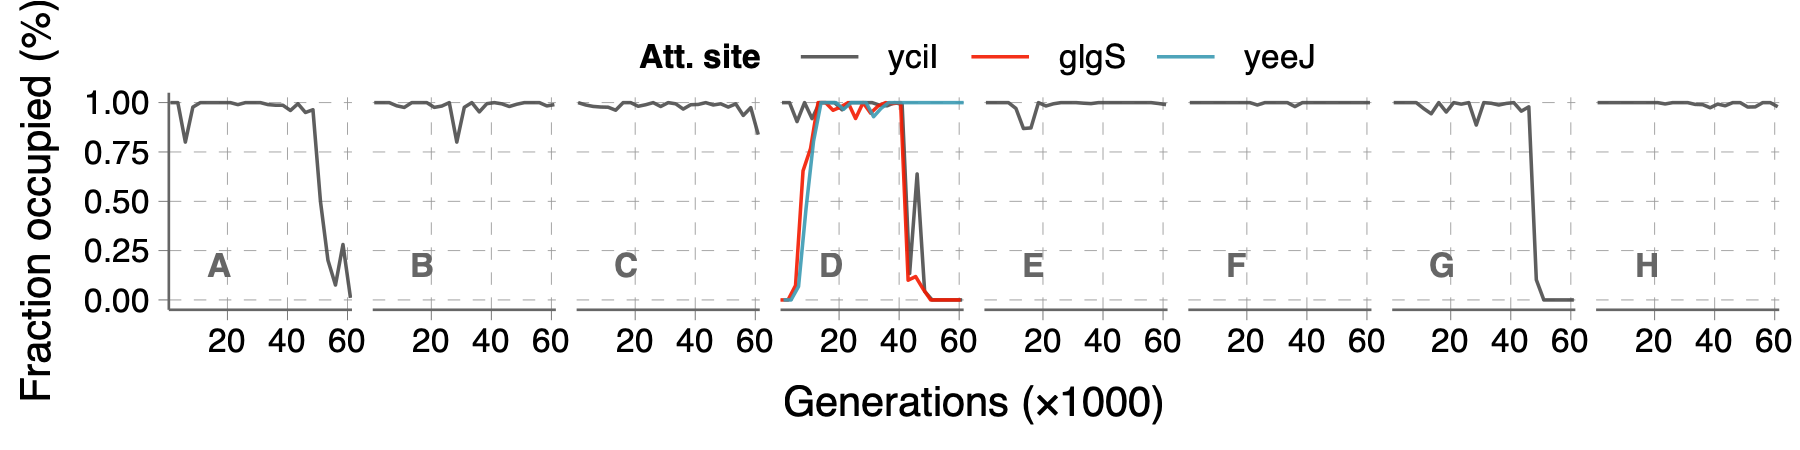

In [4]:
f =
junctions_counts %>%
    filter(site != 'phag') %>% 
    group_by(name, site) %>%
    mutate(
        n_total = sum(n),
        freq = n / n_total
        ) %>%
    ungroup() %>%
    filter(status == 'P', pop != 'W') %>% 
    complete(nesting(pop, site), gen = 0:24, fill = list(freq = 0)) %>% 

    # Remove inoccupied sites
    group_by(pop, site) %>%
    filter(max(freq) > 0.3) %>% 
    ungroup() %>% 
    mutate(freq = ifelse(is.na(freq), 0, freq))

# Correct for cross-contaminations
f = f %>% mutate(
    freq = case_when(
        gen == 0 & site == 'yciI' ~ 1, # WT is 100% yciI
        name %in% c('EB21', 'EB22') ~ 1, # D21 to B21-22
        name %in% c('ED06', 'ED09', 'ED11') ~ 1, # H6 to D6
        T ~ freq
    )
)

size(1.5, 6)
library(ggh4x)

f %>% 
    #filter(pop %in% c('A', 'B', 'C', 'D', 'F', 'G')) %>% 

ggplot() + 
    aes(
        gen*2.5 + as.integer(as.factor(site))*0.5,
        col = fct_reorder(site, site!='yciI'),
        y = freq,
        ) +

    facet_wrap2(~pop, strip = strip_tag(just=c(0.15,0.05)), ncol = 8) +
    theme(legend.box.spacing = unit(0,'mm'),
        legend.text = element_text(size=8),
        legend.title = element_text(face='bold', size=8),
        legend.position = 'top',
        strip.text = element_text(color = 'grey40', face = 'bold'), 
        strip.background = eb
    ) +

    scale_x_continuous(expand = c(0,0)) +
    geom_line(lwd = 0.4, alpha = 0.9) +

    scale_color_manual(values = c('glgS' = pal[5], 'yciI' = 'grey30', 'yeeJ' = pal[1])) +

    labs(x = 'Generations (×1000)', y = 'Fraction occupied (%)', col = 'Att. site')

psave('Plots/attachment_site_occupancy')

The drops in alternative sites for D are clearly due to the temporary cross-contaminations (that come with exactly this pattern).

In [5]:
library(ggtext)

Warning message:
“The `scale_name` argument of `discrete_scale()` is deprecated as of ggplot2
3.5.0.”


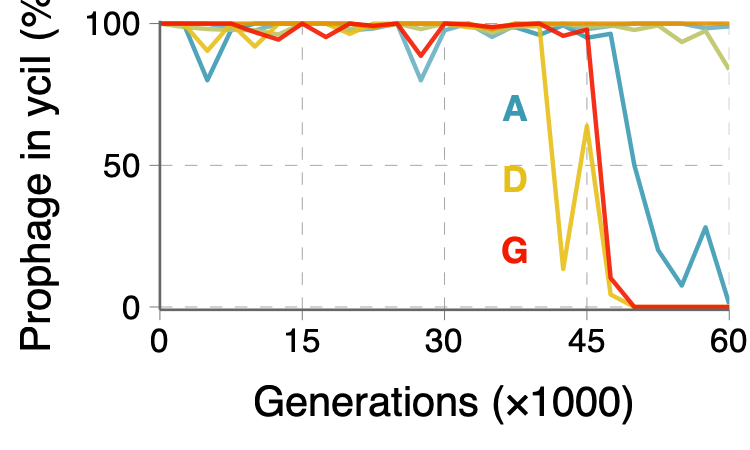

In [6]:
size(3, 6)
#library(ggh4x)

letters = data.frame(
    pop = c('A', 'D', 'G'),
    gen = 15,
    freq = (0.7 - seq(0, 0.5, length.out = 3))
)

attachment_site_occupancy_pooled =
f %>% 
    filter(site == 'yciI') %>% 
    filter(pop %in% c('A', 'B', 'C', 'D', 'F', 'G')) %>% 

ggplot() + 
    aes(
        gen*2.5,
        col = pop, label = pop,
        y = freq*100,
        ) +

    #facet_wrap2(~pop, strip = strip_tag(just=c(0.15,0.05)), ncol = 4) +
    theme(
        strip.text = element_text(color = 'grey40', face = 'bold'), 
        strip.background = eb,
        legend.title = eb,
        #axis.text.x = element_text(size=7),
        #axis.text.y = element_text(size=7),
        #axis.title.y = ggtext::element_markdown()
    ) + nl +

    scale_x_continuous(breaks = seq(0, 60, 15), expand = expansion(mult=0.0)) +
    scale_y_continuous(expand = expansion(mult=0.01), breaks = c(0, 50, 100)) +
    geom_line(lwd = 0.5, alpha = 0.9) +

    geom_text(data = letters, fontface = 'bold', size = 3) +

    labs(x = 'Generations (×1000)', y = 'Prophage in yciI (%)', col = 'Pop.')

size(1.5, 2.5)
attachment_site_occupancy_pooled
psave('Plots/attachment_site_occupancy_pooled')

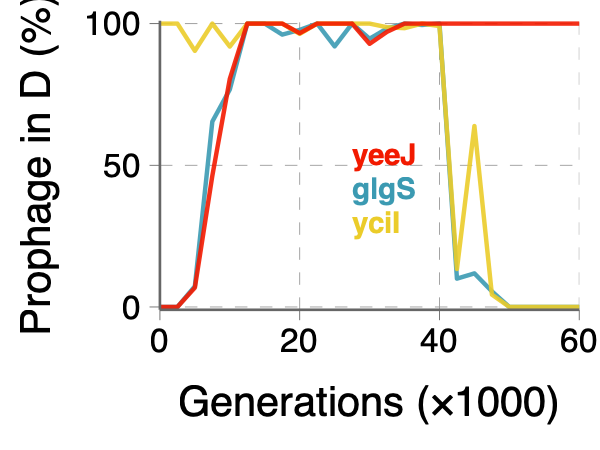

In [7]:
library(ggh4x)

xpos = 11
offset = 0.3
coeff = 0.12

sites = tribble(
    ~gen, ~freq, ~site,
    xpos, offset+coeff*0, 'yciI',
    xpos, offset+coeff*1, 'glgS',
    xpos, offset+coeff*2, 'yeeJ'
)

attachment_site_occupancy_D =
f %>% 
    #filter(site == 'yciI') %>% 
    filter(pop %in% c('D')) %>% 

ggplot() + 
    aes(
        gen*2.5,
        col = site, label = site,
        y = freq*100,
        ) +

    #facet_wrap2(~pop, strip = strip_tag(just=c(0.15,0.05)), ncol = 4) +
    theme(
        strip.text = element_text(color = 'grey40', face = 'bold'), 
        strip.background = eb,
        #axis.title.y = ggtext::element_markdown(),
        legend.title = element_text(face='bold', size=8),
        legend.text = element_text(size=8)
    ) + nl +

    scale_x_continuous(expand = c(0,0), breaks = seq(0, 60, 20)) +
    scale_y_continuous(expand = expansion(mult=0.01), breaks = c(0, 50, 100)) +
    geom_line(lwd = 0.5, alpha = 0.9) +

    geom_text(
        data = sites, 
        fontface = 'bold', size = 2.5, hjust=0
    ) +

    labs(x = 'Generations (×1000)', y = 'Prophage in D (%)', col = 'Attachment\nsite')

size(1.5, 2)
attachment_site_occupancy_D
psave('Plots/attachment_site_occupancy_D_all_sites')